In [50]:
import pandas as pd
df = pd.read_csv("movies_data.csv", encoding="latin-1")
df.head()

,Name,Year,Duration,Genre,Rating,Votes,Director,Actor 1,Actor 2,Actor 3
0,#Gadhvi (He thought he was Gandhi),2019,109,Drama,7.0,8,Gaurav Bakshi,Rasika Dugal,Vivek Ghamande,Arvind Jangid
1,#Yaaram,2019,110,"Comedy, Romance",4.4,35,Ovais Khan,Prateik,Ishita Raj,Siddhant Kapoor
2,...Aur Pyaar Ho Gaya,1997,147,"Comedy, Drama, Musical",4.7,827,Rahul Rawail,Bobby Deol,Aishwarya Rai Bachchan,Shammi Kapoor
3,...Yahaan,2005,142,"Drama, Romance, War",7.4,1086,Shoojit Sircar,Jimmy Sheirgill,Minissha Lamba,Yashpal Sharma
4,?: A Question Mark,2012,82,"Horror, Mystery, Thriller",5.6,326,Allyson Patel,Yash Dave,Muntazir Ahmad,Kiran Bhatia


In [51]:
df.shape

(5659, 10)

In [52]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5659 entries, 0 to 5658
Data columns (total 10 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Name      5659 non-null   object 
 1   Year      5659 non-null   int64  
 2   Duration  5659 non-null   int64  
 3   Genre     5659 non-null   object 
 4   Rating    5659 non-null   float64
 5   Votes     5659 non-null   int64  
 6   Director  5659 non-null   object 
 7   Actor 1   5659 non-null   object 
 8   Actor 2   5659 non-null   object 
 9   Actor 3   5659 non-null   object 
dtypes: float64(1), int64(3), object(6)
memory usage: 442.2+ KB


In [53]:
df.isnull().sum()

,0
Name,0
Year,0
Duration,0
Genre,0
Rating,0
Votes,0
Director,0
Actor 1,0
Actor 2,0
Actor 3,0


In [54]:
df.duplicated().sum()

np.int64(0)

In [55]:
df["Year"] = df["Year"].astype(str).str.extract(r"(\d{4})")[0].astype(float)
df["Duration"] = df["Duration"].astype(str).str.extract(r"(\d+)")[0].astype(float)
df["Votes"] = pd.to_numeric(df["Votes"].astype(str).str.replace(",", ""), errors="coerce")
df["Rating"] = pd.to_numeric(df["Rating"], errors="coerce")

In [56]:
df = df.drop_duplicates()
df = df.dropna(subset=["Rating", "Votes", "Year"])
df.shape

(5659, 10)

In [57]:
df["Primary Genre"] = df["Genre"].str.split(",").str[0].str.strip()
df["Decade"] = (df["Year"] // 10 * 10).astype(int).astype(str) + "s"
df["Is Drama"] = (df["Primary Genre"] == "Drama").astype(int)
df.head()

,Name,Year,Duration,Genre,Rating,Votes,Director,Actor 1,Actor 2,Actor 3,Primary Genre,Decade,Is Drama
0,#Gadhvi (He thought he was Gandhi),2019.0,109.0,Drama,7.0,8,Gaurav Bakshi,Rasika Dugal,Vivek Ghamande,Arvind Jangid,Drama,2010s,1
1,#Yaaram,2019.0,110.0,"Comedy, Romance",4.4,35,Ovais Khan,Prateik,Ishita Raj,Siddhant Kapoor,Comedy,2010s,0
2,...Aur Pyaar Ho Gaya,1997.0,147.0,"Comedy, Drama, Musical",4.7,827,Rahul Rawail,Bobby Deol,Aishwarya Rai Bachchan,Shammi Kapoor,Comedy,1990s,0
3,...Yahaan,2005.0,142.0,"Drama, Romance, War",7.4,1086,Shoojit Sircar,Jimmy Sheirgill,Minissha Lamba,Yashpal Sharma,Drama,2000s,1
4,?: A Question Mark,2012.0,82.0,"Horror, Mystery, Thriller",5.6,326,Allyson Patel,Yash Dave,Muntazir Ahmad,Kiran Bhatia,Horror,2010s,0


In [58]:
df.describe()

,Year,Duration,Rating,Votes,Is Drama
count,5659.000000,5659.000000,5659.000000,5659.000000,5659.000000
mean,1996.247570,133.439124,5.898533,2697.649585,0.325499
std,19.741839,25.319939,1.381165,13651.503584,0.468602
min,1931.000000,21.000000,1.100000,5.000000,0.000000
25%,1983.000000,119.000000,5.000000,30.000000,0.000000
50%,2002.000000,135.000000,6.100000,131.000000,0.000000
75%,2013.000000,150.000000,6.900000,922.500000,1.000000
max,2021.000000,321.000000,10.000000,591417.000000,1.000000


In [59]:
df.to_csv("cleaned_movies.csv", index=False)
from google.colab import files
files.download("cleaned_movies.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [60]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

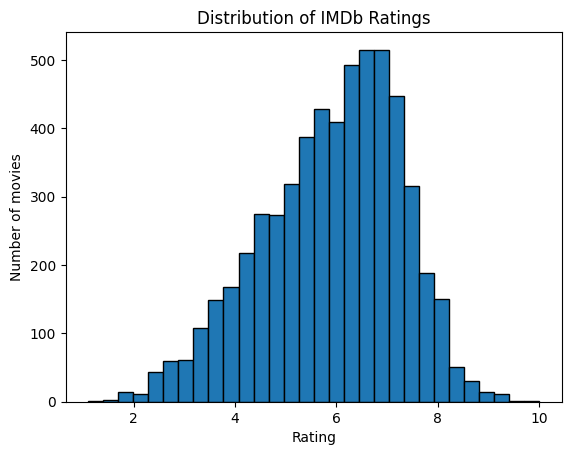

In [61]:
plt.hist(df["Rating"], bins=30, edgecolor="black")
plt.title("Distribution of IMDb Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of movies")
plt.show()

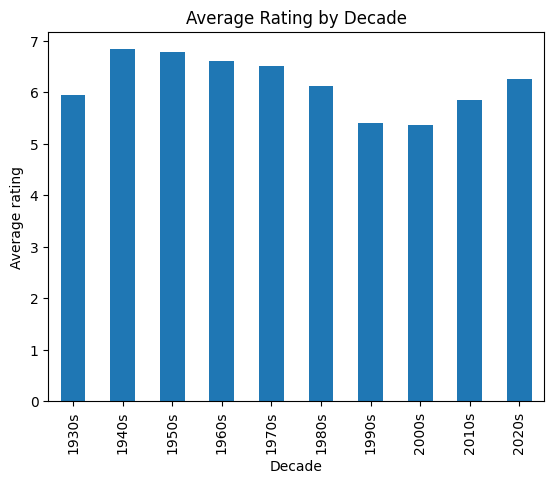

In [62]:
df.groupby("Decade")["Rating"].mean().plot(kind="bar")
plt.title("Average Rating by Decade")
plt.ylabel("Average rating")
plt.show()

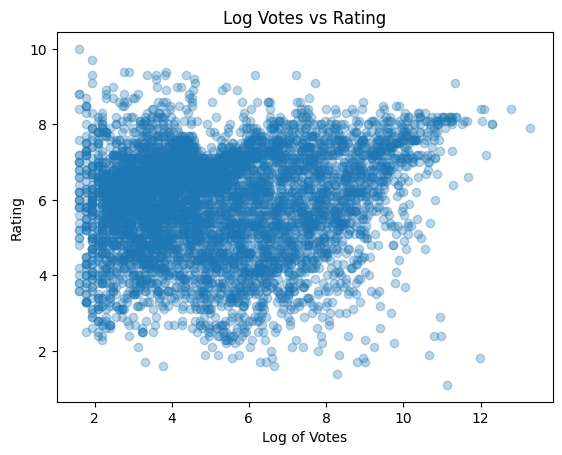

In [63]:
df["LogVotes"] = np.log(df["Votes"])
plt.scatter(df["LogVotes"], df["Rating"], alpha=0.3)
plt.title("Log Votes vs Rating")
plt.xlabel("Log of Votes")
plt.ylabel("Rating")
plt.show()

In [64]:
df[["Year", "Duration", "Rating", "LogVotes"]].corr()

,Year,Duration,Rating,LogVotes
Year,1.000000,-0.327567,-0.204642,0.368700
Duration,-0.327567,1.000000,0.001839,0.212037
Rating,-0.204642,0.001839,1.000000,0.134179
LogVotes,0.368700,0.212037,0.134179,1.000000


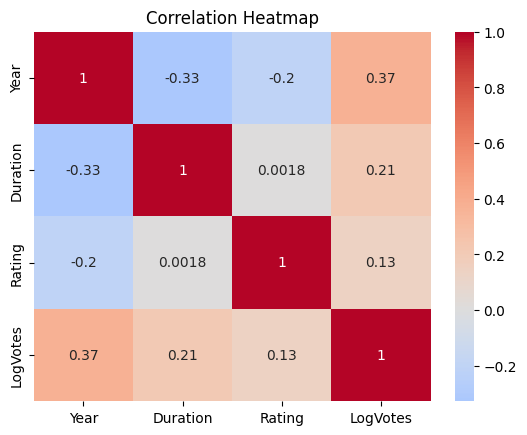

In [65]:
sns.heatmap(df[["Year", "Duration", "Rating", "LogVotes"]].corr(), annot=True, cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.show()

In [66]:
from scipy import stats

n = 10
p = df["Is Drama"].mean()
groups = len(df) // n
sums = df["Is Drama"].values[:groups*n].reshape(groups, n).sum(axis=1)
obs = np.bincount(sums, minlength=n+1)
print(p, groups)
print(obs)

0.3254992048065029 565
[ 21  55 123 126 123  56  42  15   4   0   0]


In [67]:
x = np.arange(n+1)
lam = n * p
binom_p = stats.binom.pmf(x, n, p)
pois_p = stats.poisson.pmf(x, lam)
pois_p[-1] += stats.poisson.sf(n, lam)


In [68]:
exp_b = binom_p * groups
exp_p = pois_p * groups

In [69]:
def merge(a):
  return np.append(a[:8], a[8:].sum())
obs_m, eb, ep = merge(obs), merge(exp_b), merge(exp_p)

In [70]:
print("Binomial:", stats.chisquare(obs_m, eb, ddof=1))
print("Poisson: ", stats.chisquare(obs_m, ep, ddof=1))

Binomial: Power_divergenceResult(statistic=np.float64(31.97159506152375), pvalue=np.float64(4.111133419221344e-05))
Poisson:  Power_divergenceResult(statistic=np.float64(15.193257938266383), pvalue=np.float64(0.033600389938369966))


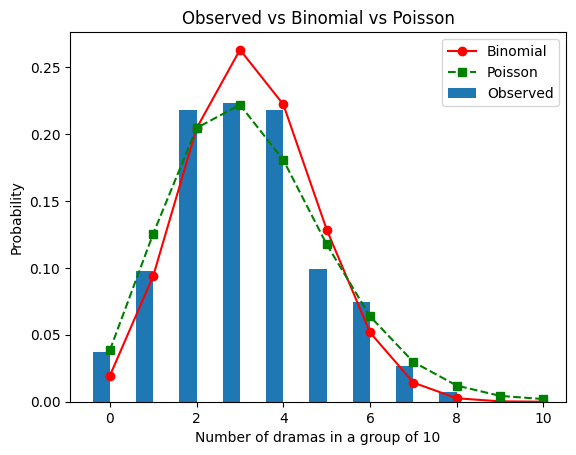

In [71]:
plt.bar(x - 0.2, obs/groups, width=0.4, label="Observed")
plt.plot(x, binom_p, "o-", color="red", label="Binomial")
plt.plot(x, pois_p, "s--", color="green", label="Poisson")
plt.xlabel("Number of dramas in a group of 10")
plt.ylabel("Probability")
plt.legend()
plt.title("Observed vs Binomial vs Poisson")
plt.show()

In [72]:
print("Mean of group counts:", sums.mean())
print("Variance of group counts:", sums.var())
print("Binomial variance would be:", n * p * (1 - p))


Mean of group counts: 3.256637168141593
Variance of group counts: 2.7606860364946355
Binomial variance would be: 2.195494724768372


Baseline RMSE: 1.361076019720818
Linear R2: 0.1941326739230279
Linear RMSE: 1.2215808203666905
Forest R2: 0.27160473284217657
Forest RMSE: 1.1613790543278806
From-scratch R2: 0.19413267392302624


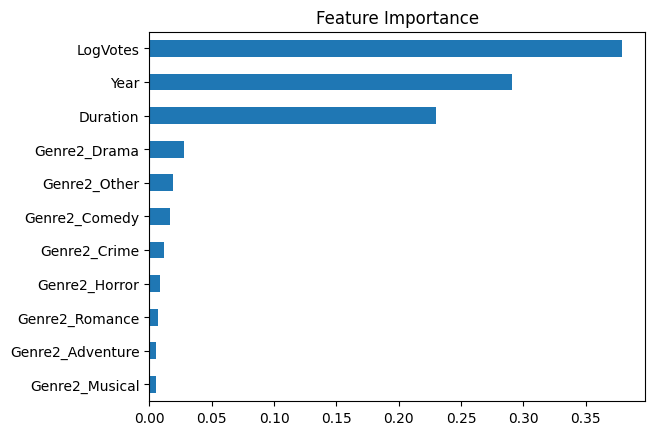

In [73]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error

df["LogVotes"] = np.log(df["Votes"])
top = df["Primary Genre"].value_counts().head(8).index
d = df.copy()
d["Genre2"] = d["Primary Genre"].where(d["Primary Genre"].isin(top), "Other")
X = pd.get_dummies(d[["Year", "Duration", "LogVotes", "Genre2"]], columns=["Genre2"], drop_first=True).astype(float)
y = d["Rating"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

base = np.full(len(y_test), y_train.mean())
print("Baseline RMSE:", np.sqrt(mean_squared_error(y_test, base)))

lr = LinearRegression().fit(X_train, y_train)
pred = lr.predict(X_test)
print("Linear R2:", r2_score(y_test, pred))
print("Linear RMSE:", np.sqrt(mean_squared_error(y_test, pred)))

rf = RandomForestRegressor(n_estimators=100, random_state=42).fit(X_train, y_train)
pred_rf = rf.predict(X_test)
print("Forest R2:", r2_score(y_test, pred_rf))
print("Forest RMSE:", np.sqrt(mean_squared_error(y_test, pred_rf)))

Xs = X_train.values
mu, sd = Xs.mean(axis=0), Xs.std(axis=0)
Xb = np.c_[np.ones(len(Xs)), (Xs - mu) / sd]
yt = y_train.values
w = np.zeros(Xb.shape[1])
for i in range(2000):
    grad = (2 / len(yt)) * Xb.T @ (Xb @ w - yt)
    w -= 0.05 * grad
Xt = np.c_[np.ones(len(X_test)), (X_test.values - mu) / sd]
print("From-scratch R2:", r2_score(y_test, Xt @ w))

pd.Series(rf.feature_importances_, index=X.columns).sort_values().plot(kind="barh")
plt.title("Feature Importance")
plt.show()

In [74]:
df[["Year", "Duration", "Rating", "LogVotes"]].corr()

,Year,Duration,Rating,LogVotes
Year,1.000000,-0.327567,-0.204642,0.368700
Duration,-0.327567,1.000000,0.001839,0.212037
Rating,-0.204642,0.001839,1.000000,0.134179
LogVotes,0.368700,0.212037,0.134179,1.000000


In [75]:
df.groupby("Primary Genre")["Rating"].agg(["mean", "count"]).query("count >= 50").sort_values("mean", ascending=False).head(5)

,mean,count
Primary Genre,,
Biography,6.697619,84
Family,6.296154,52
Drama,6.248697,1842
Adventure,6.181905,105
Crime,6.124723,271


In [76]:
df.to_csv("cleaned_movies.csv", index=False)
from google.colab import files
files.download("cleaned_movies.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>